In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [7]:
data = pd.read_csv("../data/Superstore.csv", encoding="latin1")
data["Order Date"] = pd.to_datetime(data["Order Date"])
print(data["Order Date"])

0      2016-11-08
1      2016-11-08
2      2016-06-12
3      2015-10-11
4      2015-10-11
          ...    
9989   2014-01-21
9990   2017-02-26
9991   2017-02-26
9992   2017-02-26
9993   2017-05-04
Name: Order Date, Length: 9994, dtype: datetime64[us]


In [8]:
totalRev = data["Sales"].sum()
totalProfit = data["Profit"].sum()
topCategory = data.groupby("Category")["Sales"].count().idxmax()
topCategoryByRev = data.groupby("Category")["Sales"].sum().idxmax()
topSubCategory = data.groupby("Sub-Category")["Sales"].count().idxmax()
topSubCategoryByRev = data.groupby("Sub-Category")["Sales"].sum().idxmax()
topRegion = data.groupby("Region")["Sales"].sum().idxmax()
lossProduct = data.groupby("Product Name")["Profit"].sum().idxmin()
topMonth = data.groupby(data["Order Date"].dt.to_period("M"))["Sales"].count().idxmax()
avgDiscount = data["Discount"].mean()
topCustomer = data.groupby("Customer Name")["Sales"].sum().idxmax()
disProCorr = data["Discount"].corr(data["Profit"])

print("========== RETAIL PULSE ANALYSIS ==========")
print("Total Revenue:", totalRev)
print("Total Profit:", totalProfit)
print("Top Category:", topCategoryByRev)
print("Top Sub-Category:", topSubCategoryByRev)
print("Top Region:", topRegion)
print("Highest Sales Month:", topMonth)
print("Average Discount:", avgDiscount)
print("Top Customer:", topCustomer)
print("==========================================")

========== RETAIL PULSE ANALYSIS ==========
Total Revenue: 2297200.8603
Total Profit: 286397.0217
Top Category: Technology
Top Sub-Category: Phones
Top Region: West
Highest Sales Month: 2017-12
Average Discount: 0.1562027216329798
Top Customer: Sean Miller


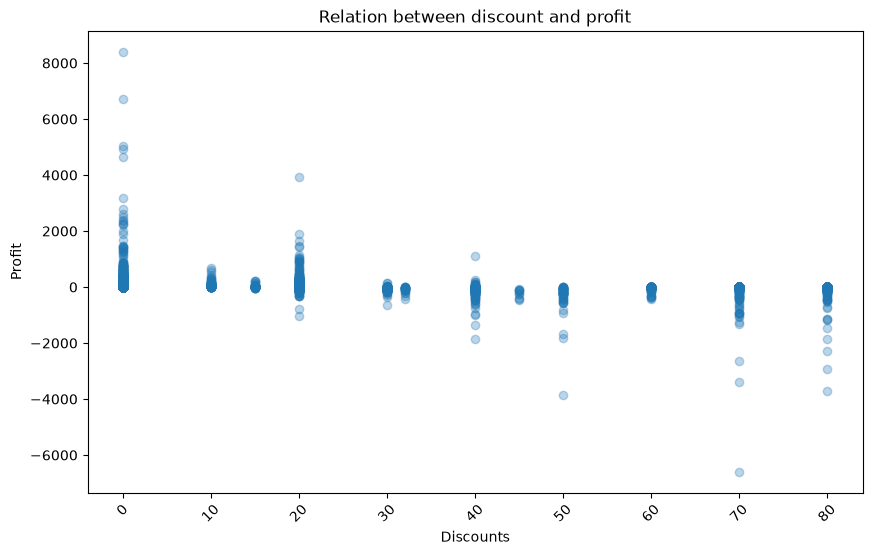

In [9]:
plt.figure(figsize=(10,6))
plt.scatter(data["Discount"]*100,data["Profit"],alpha=0.3)
plt.xlabel("Discounts")
plt.ylabel("Profit")
plt.title("Relation between discount and profit")
plt.xticks(rotation=45)
plt.show()

In [10]:
#Spoiling Dataset with a maths
sales = data["Sales"].to_numpy()
meanSale = np.mean(sales)
sdSales = np.std(sales,ddof=1)

p25 = np.percentile(sales, 25)
p50 = np.percentile(sales, 50)
p75 = np.percentile(sales, 75)
p90 = np.percentile(sales, 90)

total_sales = np.sum(data["Sales"].to_numpy())
total_profit = np.sum(data["Profit"].to_numpy())

profit_margin = np.divide(total_profit, total_sales) * 100

print("25th Percentile:", p25)
print("50th Percentile:", p50)
print("75th Percentile:", p75)
print("90th Percentile:", p90)
print("Total Sales:", total_sales)
print("Total Profit:", total_profit)
print("Profit Margin:", profit_margin, "%")

25th Percentile: 17.28
50th Percentile: 54.489999999999995
75th Percentile: 209.94
90th Percentile: 572.7060000000001
Total Sales: 2297200.8603
Total Profit: 286397.0217
Profit Margin: 12.467217240315605 %
